# 03 · Modelagem e avaliação

## Objetivo

Treinar e comparar os **7 algoritmos usados no artigo** (Lessmeier et al., 2016) e o **ensemble** que combina todos eles. A tarefa é classificar o estado do rolamento em três classes: **saudável (0)**, **dano no anel externo (1)** e **dano no anel interno (2)**. Cada algoritmo é testado com três conjuntos de features:

| Conjunto | Sinais usados | Prefixos das colunas |
|---|---|---|
| **MCS** | as duas correntes de fase do motor | `i1__`, `i2__` |
| **Vibração** | acelerômetro na carcaça do rolamento | `vib__` |
| **Fusão** | correntes + vibração (não está no artigo) | `i1__`, `i2__`, `vib__` |

Cada amostra é uma medição de 4 s. Cada rolamento tem 20 medições por condição de operação.

## Algoritmos (implementados em `rolamentos.py`)

| Sigla | Modelo no artigo | Implementação aqui |
|---|---|---|
| CART | árvore de decisão | `DecisionTreeClassifier` |
| RF | random forest | `RandomForestClassifier` (300 árvores) |
| BT | boosted trees | `HistGradientBoostingClassifier` |
| NN | rede neural | `MLPClassifier` (1 camada oculta, 32 neurônios) |
| SVM | SVM ajustado por PSO | `SVC` (RBF) ajustado por busca em grade |
| ELM | extreme learning machine | `ELMClassifier`  |
| kNN | k vizinhos mais próximos | `KNeighborsClassifier` |
| Ensemble | votação majoritária | maioria das 7 predições acima |

## Cuidados metodológicos

**1. Divisão por rolamento, nunca por medição.**
As medições de um mesmo rolamento são muito parecidas entre si. Numa divisão aleatória por arquivo, o mesmo rolamento aparece no treino e no teste. O modelo aprende a reconhecer *o rolamento*, e não *o tipo de dano*, e a acurácia fica artificialmente alta. Aqui, todo rolamento está **inteiro no treino ou inteiro no teste**. Isso mede o que importa na prática: o desempenho em rolamentos que o modelo nunca viu.

**2. Pipeline ajustado só com o treino de cada fold.**
Cada modelo roda dentro do mesmo pipeline:

`imputação (mediana) → padronização (z-score) → remoção de features com |r| ≥ 0,95 → seleção por distância de separação (d̄ ≥ 0,7, mínimo 3) → classificador`

Todas as etapas aprendem os parâmetros (medianas, médias, quais features ficam) **apenas com os rolamentos de treino**. Nenhuma informação do teste influencia a seleção de features, o que evita vazamento de dados.

**3. Hiperparâmetros por validação interna agrupada.**
O artigo ajustou o SVM com PSO. Aqui, SVM (`C`, `gamma`) e kNN (`n_neighbors`) são ajustados por busca em grade com `GroupKFold` de 3 partes **dentro do conjunto de treino**, também separado por rolamento. A métrica é a acurácia balanceada. O conjunto de teste nunca participa da escolha.

**4. Ensemble sem treino extra.**
O ensemble é a votação majoritária das predições dos 7 modelos já treinados. Em caso de empate, vence a classe votada primeiro, na ordem da tabela acima.

**5. Métricas.**
- **Acurácia** média entre os folds (a métrica do artigo);
- **Acurácia balanceada** e **F1 macro**, que não são enganadas por classes de tamanhos diferentes;
- **Matriz de confusão** somada sobre todos os folds;
- **Taxa de acerto por rolamento**, para identificar quais rolamentos causam os erros.

## Experimentos

O experimento da seção 7.2 do artigo (treinar com danos artificiais e testar com danos reais) não é reproduzido, porque a pasta de dados não contém os rolamentos KA com dano artificial.

| # | Experimento | Dados | Validação | Referência no artigo |
|---|---|---|---|---|
| 1 | **Cenário B:** danos reais | condição 0 (`N15_M07_F10`), 15 rolamentos da Tabela 10 (5 por classe) | 10 combinações: 3 rolamentos por classe no treino, 2 no teste | Seção 7.3, Tabela 11 |
| 2 | **Cenário C:** danos múltiplos | cenário B + KB23, KB24 (anel interno) e KB27 (anel externo) | 20 folds: KB23 e KB24 se alternam entre treino e teste; KB27 fica só no teste | Seção 7.4, Tabela 13 |
| 3 | **Critério de seleção** | igual ao cenário B | igual ao cenário B | compara a fórmula do artigo com a variante `razao` |
| 4 | **Quatro condições juntas** | 15 rolamentos da Tabela 10, todas as condições | igual ao cenário B | extensão: com e sem rotação, torque e força como features de contexto |
| 5 | **Detecção binária** | todos os rolamentos reais e saudáveis, todas as condições | `StratifiedGroupKFold` (5 folds por rolamento) | extensão: saudável × danificado |

**Valores do artigo para comparação** (acurácia média do ensemble):

| | MCS | Vibração |
|---|---|---|
| Tabela 11 (cenário B) | 93,3 % | 98,3 % |
| Tabela 13 (cenário C) | 86,3 % | 91,3 % |

- **Tabela 11 (cenário B):** saudáveis, anel externo e anel interno, só com danos reais simples.
- **Tabela 13 (cenário C):** igual ao cenário B, mas com os rolamentos KB, que têm dano nos dois anéis.


## 1. Configuração
`N_JOBS = -1` paraleliza **entre folds**. Os modelos rodam com 1 núcleo cada, para não disputar CPU.

In [13]:
import warnings
from pathlib import Path

import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

import rolamentos as R

from IPython.display import Markdown, display

ESQUEMA = "artigo"  # "artigo" (3 classes) ou "4classes"
METODO_SEL = "razao"  
LIMIAR_CORR = 0.95  # remove pares com |r| >= LIMIAR_CORR. Use 1.01 para desligar o filtro
LIMIAR_SEL = 0.7    # mantém features com d̄ >= LIMIAR_SEL. Use 0.0 para manter todas

warnings.filterwarnings("ignore", category=UserWarning)
ARQUIVO_DATASET = Path(f"dataset_rotulado_{ESQUEMA}.csv")
PASTA_RESULTADOS = Path("resultados")
PASTA_RESULTADOS.mkdir(exist_ok=True)
CONDICAO_ARTIGO = "N15_M07_F10"
N_JOBS = -1

df = pd.read_csv(ARQUIVO_DATASET)
esquema = "4classes" if df["classe"].max() == 3 else "artigo"
nomes = R.NOMES_CLASSES[esquema]
modelos = R.criar_modelos(seed=42, metodo_sel=METODO_SEL,
                          limiar_corr=LIMIAR_CORR, limiar_sel=LIMIAR_SEL)
print(df.shape, "| esquema de rótulos:", esquema)

if ESQUEMA != esquema:
    raise ValueError("O esquema do DF importado e diferente do esquema selecionado!!")

(1600, 100) | esquema de rótulos: artigo


## 2. Funções auxiliares do notebook
- `rodar_por_sensor`: roda o mesmo experimento para MCS, Vibração e Fusão e monta uma tabela modelo × sensor com a acurácia média, no formato das Tabelas 11 e 13 do artigo.
- `plot_confusao`: matriz de confusão somada sobre todos os folds (linhas = classe real, ao contrário da figura do artigo).

In [14]:
def rodar_por_sensor(dados, divisoes, modelos, grupos=R.GRUPOS_SENSORES, extras=(), alvo="classe"):
    tabela, predicoes, selecoes = {}, {}, {}
    for nome, sensores in grupos.items():
        colunas = R.colunas_features(dados, sensores) + list(extras)
        preds, sel = R.avaliar(dados, colunas, divisoes, modelos, alvo=alvo,
                               grades=R.GRADES, n_jobs=N_JOBS)
        tabela[nome] = R.resumo(preds)[("acuracia", "mean")]
        predicoes[nome], selecoes[nome] = preds, sel
    return (pd.DataFrame(tabela) * 100).round(1), predicoes, selecoes


def plot_confusao(preds, modelo, titulo, rotulos):
    cm = R.matriz_confusao(preds, modelo, rotulos=list(rotulos))
    ConfusionMatrixDisplay(cm, display_labels=list(rotulos.values())).plot(cmap="Blues", colorbar=False)
    plt.title(titulo); plt.xticks(rotation=20); plt.tight_layout()

## 3. Experimento 1 · Cenário B (Tabela 10 / 11 do artigo)
- Dados: condição 0, 15 rolamentos da Tabela 10 (5 saudáveis, 5 com anel externo, 5 com anel interno), uma amostra por medição.
- Validação: as 10 combinações (2 posições de teste em 5), aplicadas às 3 classes ao mesmo tempo.

Resultado do artigo para comparação (Tabela 11, acurácia %): MCS: RF 83,3, Ensemble 93,3. Vibração: CART/RF/Ensemble 98,3.

In [15]:
rol_B = [r for lista in R.TABELA_10.values() for r in lista]
dados_B = df[df["rolamento"].isin(rol_B) & (df["condicao"] == CONDICAO_ARTIGO)].reset_index(drop=True)
div_B = R.divisoes_artigo(dados_B, cenario="B")
print(f"{len(dados_B)} amostras | {len(div_B)} folds | exemplo: {div_B[0][0]}")

tab_B, preds_B, sel_B = rodar_por_sensor(dados_B, div_B, modelos)
tab_B

300 amostras | 10 folds | exemplo: teste=K001,K002,KA04,KA15,KI04,KI14


,MCS,Vibracao,Fusao
modelo,,,
BT,37.4,64.0,62.2
CART,36.2,58.8,58.8
ELM,35.3,65.2,63.5
Ensemble,35.3,72.9,73.0
NN,33.8,74.4,74.4
RF,36.3,73.4,73.4
SVM,31.4,75.9,74.3
kNN,33.5,72.8,74.2


## Experimento 1b · Cenário B binário (sem defeito × com defeito)
Mesmos dados e mesmas 10 divisões do experimento 1, mas o alvo é a coluna `danificado` (0 = saudável, 1 = qualquer dano). Assim dá para ver se o modelo pelo menos **detecta** o dano, mesmo sem saber em qual anel ele está.

Cada teste tem 2 rolamentos saudáveis e 4 danificados. Um modelo que sempre responde "danificado" já acerta 67 %. Por isso a métrica principal aqui é a **acurácia balanceada**: a média do acerto em cada classe, em que esse modelo "preguiçoso" fica em 50 %.

MCS              Vibracao                 Fusao             
         acuracia acuracia_bal acuracia acuracia_bal acuracia acuracia_bal
modelo                                                                    
CART         64.6         58.8     74.5         65.9     73.0         64.4
RF           72.7         67.5     73.8         66.1     74.0         66.2
BT           62.8         57.9     68.4         62.4     70.6         62.8
NN           72.4         67.9     77.6         70.2     80.5         74.2
SVM          70.2         65.7     75.2         67.9     75.2         67.9
ELM          78.3         75.7     65.5         60.1     66.1         58.9
kNN          73.8         69.4     76.2         68.6     74.0         67.0
Ensemble     72.3         67.4     75.8         68.2     76.4         68.8

,taxa_acerto,n
rolamento,,
K005,0.0000,80
K002,0.0375,80
K004,0.2500,80
KA15,0.7000,80
KI18,0.7500,80
KA22,0.7500,80
KI04,0.9375,80
KI21,0.9375,80
KA16,1.0000,80


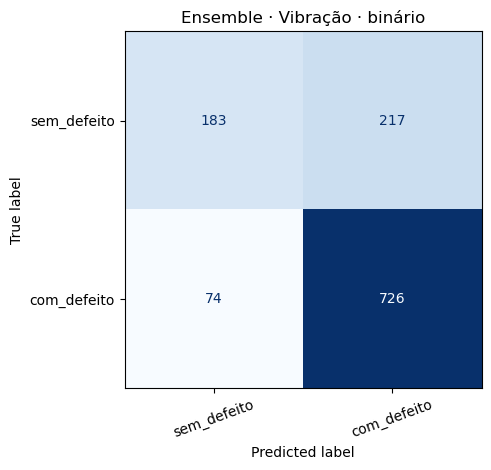

In [16]:
modelos_bin = R.criar_modelos(seed=42, metodo_sel="artigo",
                              limiar_corr=LIMIAR_CORR, limiar_sel=LIMIAR_SEL)
preds_bin_B, tabela = {}, {}
for nome, sensores in R.GRUPOS_SENSORES.items():
    preds, _ = R.avaliar(dados_B, R.colunas_features(dados_B, sensores), div_B, modelos_bin,
                         alvo="danificado", grades=R.GRADES, n_jobs=N_JOBS)
    preds_bin_B[nome] = preds
    r = R.resumo(preds)
    tabela[(nome, "acuracia")] = r[("acuracia", "mean")]
    tabela[(nome, "acuracia_bal")] = r[("acuracia_bal", "mean")]

ordem = list(modelos_bin) + ["Ensemble"]  # CART, RF, BT, NN, SVM, ELM, kNN, Ensemble
display((pd.DataFrame(tabela).reindex(ordem) * 100).round(1))

plot_confusao(preds_bin_B["Vibracao"], "Ensemble", "Ensemble · Vibração · binário",
              {0: "sem_defeito", 1: "com_defeito"})
R.acerto_por(preds_bin_B["Vibracao"], "Ensemble")

Conclusão · Experimento 1b (binário: sem defeito × com defeito):

O modelo binário **não ficou mais fácil** que o de 3 classes. O gargalo está em **detectar** o dano, e não em identificar em qual anel ele está.


### Estabilidade da seleção
Fração dos folds em que cada feature passou pelos filtros. Uma feature escolhida em 100 % dos folds é robusta. Se o conjunto muda a cada fold, a seleção depende de quais rolamentos estão no treino, o que é sinal de pouca generalização.

In [5]:
pd.concat({s: R.frequencia_selecao(sel_B[s]) for s in ("MCS", "Vibracao")}, axis=1).fillna(0).head(20)

,MCS,Vibracao
i2__wpd_e6,0.4,0.0
i2__wpd_e7,0.4,0.0
i1__pico_a_pico,0.3,0.0
i1__wpd_e4,0.3,0.0
i2__rms,0.3,0.0
i1__entropia,0.2,0.0
i1__rms,0.2,0.0
i2__fator_folga,0.2,0.0
i2__integral_linha,0.1,0.0
i1__wpd_e7,0.1,0.0


## 4. Experimento 2 · Cenário C (danos múltiplos, Tabela 13)
Mesmo esquema do B, mais os rolamentos KB:
- KB23 e KB24 (dominante no anel interno) se alternam: um no treino, o outro no teste;
- KB27 (dominante no anel externo) fica **só no teste**, porque é o único KB de anel externo.

São 10 × 2 = 20 folds. Com `ESQUEMA = "4classes"`, os KB viram a classe 3. Como só há 3 rolamentos KB, essa classe teria 1 rolamento no treino e 2 no teste, e por isso o experimento usa o esquema do artigo.

,MCS,Vibracao,Fusao
modelo,,,
BT,32.0,66.1,66.1
CART,33.9,63.7,63.5
ELM,30.7,69.4,69.6
Ensemble,29.1,75.2,75.2
NN,28.0,76.7,76.7
RF,29.0,73.6,73.6
SVM,26.0,74.9,75.6
kNN,28.4,75.3,74.8


,taxa_acerto,n
rolamento,,
K002,0.13750,160
K005,0.16250,160
KI14,0.21250,160
KA16,0.58750,160
KB27,0.65000,400
K004,0.65625,160
KA04,0.68125,160
KA15,0.73125,160


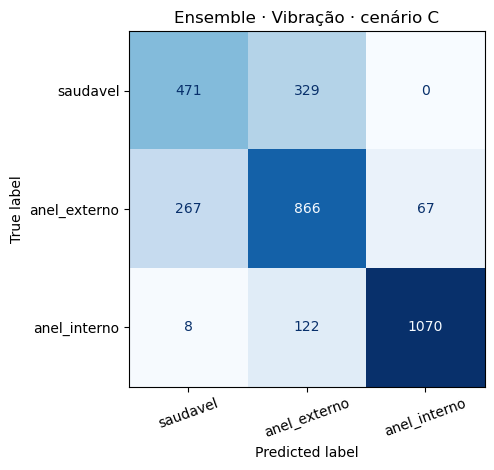

In [6]:
if esquema == "artigo":
    dados_C = df[df["rolamento"].isin(rol_B + R.MULTIPLOS) & (df["condicao"] == CONDICAO_ARTIGO)].reset_index(drop=True)
    tab_C, preds_C, _ = rodar_por_sensor(dados_C, R.divisoes_artigo(dados_C, cenario="C"), modelos)
    display(tab_C)
    plot_confusao(preds_C["Vibracao"], "Ensemble", "Ensemble · Vibração · cenário C", nomes)
    display(R.acerto_por(preds_C["Vibracao"], "Ensemble").head(8))
else:
    print("Cenário C só faz sentido com ESQUEMA='artigo' (ver texto acima).")

## 5. Experimento 3 · Critério de seleção: artigo × razão
Na fórmula do artigo, d_j também cresce com a variância **dentro** das classes, o que pode favorecer features ruidosas. A variante `razao` divide a distância entre classes pela variância interna, no estilo do critério de Fisher. Rodamos o cenário B com as duas e comparamos.

In [7]:
comparacao = {}
for metodo in ("artigo", "razao"):
    tab, _, _ = rodar_por_sensor(dados_B, div_B, R.criar_modelos(metodo_sel=metodo,
                                                     limiar_corr=LIMIAR_CORR, limiar_sel=LIMIAR_SEL))
    comparacao[metodo] = tab
pd.concat(comparacao, axis=1)

artigo                razao               
            MCS Vibracao Fusao   MCS Vibracao Fusao
modelo                                             
BT         44.8     59.3  55.4  37.4     64.0  62.2
CART       38.2     58.4  54.9  36.2     58.8  58.8
ELM        51.2     58.9  56.6  35.3     65.2  63.5
Ensemble   45.9     64.3  63.9  35.3     72.9  73.0
NN         48.7     73.3  66.8  33.8     74.4  74.4
RF         49.7     66.3  63.8  36.3     73.4  73.4
SVM        42.8     65.3  62.3  31.4     75.9  74.3
kNN        49.2     69.0  60.8  33.5     72.8  74.2

## 6. Experimento 4 · Quatro condições de operação juntas
Esta parte vai além do artigo. Usamos os mesmos 15 rolamentos e as mesmas 10 combinações, mas com **as 4 condições** misturadas (4× mais amostras). Comparamos dois casos:
- **sem contexto**: o modelo só vê as features do sinal;
- **com contexto**: acrescentamos `rotacao_rpm`, `torque_nm` e `forca_n`. Na prática essas variáveis são conhecidas pelo inversor e ajudam o modelo a descontar o efeito da condição. Elas passam pelos mesmos filtros de correlação e separação.

Depois mostramos o acerto **por condição**.

In [8]:
dados_4 = df[df["rolamento"].isin(rol_B)].reset_index(drop=True)
div_4 = R.divisoes_artigo(dados_4, cenario="B")
contexto = ["rotacao_rpm", "torque_nm", "forca_n"]
tab_sem, preds_sem, _ = rodar_por_sensor(dados_4, div_4, modelos)
tab_com, preds_com, _ = rodar_por_sensor(dados_4, div_4, modelos, extras=contexto)
display(pd.concat({"sem_contexto": tab_sem, "com_contexto": tab_com}, axis=1))
pd.concat({s: R.acerto_por(preds_sem[s], "Ensemble", "condicao")["taxa_acerto"]
           for s in ("MCS", "Vibracao")}, axis=1).round(3)

sem_contexto                com_contexto               
                  MCS Vibracao Fusao          MCS Vibracao Fusao
modelo                                                          
BT               39.4     69.0  69.0         39.4     69.0  69.0
CART             39.2     65.4  65.4         39.2     65.4  65.4
ELM              36.0     67.3  67.3         36.0     67.3  67.3
Ensemble         38.5     70.4  70.5         38.5     70.4  70.5
NN               37.3     71.9  71.9         37.3     71.9  71.9
RF               40.1     69.6  69.6         40.1     69.6  69.6
SVM              33.8     73.5  73.5         33.8     73.5  73.6
kNN              38.8     70.6  70.7         38.8     70.6  70.7

,MCS,Vibracao
condicao,,
N15_M01_F10,0.363,0.726
N15_M07_F04,0.377,0.796
N15_M07_F10,0.388,0.733
N09_M07_F10,0.413,0.562


## Experimento 4b · Três condições a 1500 rpm (sem N09_M07_F10)
Mesmos 15 rolamentos e mesmas 10 combinações da Tabela 10, mas só com as condições a **1500 rpm**: `N15_M07_F10`, `N15_M01_F10` e `N15_M07_F04` (900 amostras). A condição `N09_M07_F10` (900 rpm) fica de fora.

**Objetivo:** separar o efeito da rotação do efeito de torque e força. A rotação muda as frequências de defeito (BPFO, BPFI) e a energia da vibração. Torque e força mudam principalmente a amplitude da corrente.

Duas variantes:
- **sem contexto:** só as features dos sinais;
- **com contexto:** acrescenta `torque_nm` e `forca_n`. A rotação não entra, porque é igual em todas as amostras.

**Perguntas:**
1. Sem a condição de 900 rpm, o desempenho fica mais próximo do experimento 1 (só condição 0)?
2. Informar torque e força ajuda, principalmente na corrente?
3. Qual das três condições é a mais difícil?

900 amostras | 10 folds | condições: ['N15_M01_F10', 'N15_M07_F04', 'N15_M07_F10']


sem_contexto                com_contexto               
                  MCS Vibracao Fusao          MCS Vibracao Fusao
modelo                                                          
BT               36.7     71.9  72.2         36.7     71.9  72.2
CART             38.1     70.8  70.9         38.1     70.8  70.9
ELM              32.9     70.4  68.1         32.9     70.4  68.1
Ensemble         36.0     74.5  74.1         36.0     74.5  74.1
NN               31.6     75.9  75.5         31.6     75.9  75.5
RF               37.6     72.1  72.1         37.6     72.1  72.1
SVM              28.6     77.5  75.4         28.6     77.5  75.4
kNN              34.9     73.3  73.9         34.9     73.3  73.9

,MCS,Vibracao
condicao,,
N15_M01_F10,0.322,0.713
N15_M07_F10,0.378,0.723
N15_M07_F04,0.382,0.798


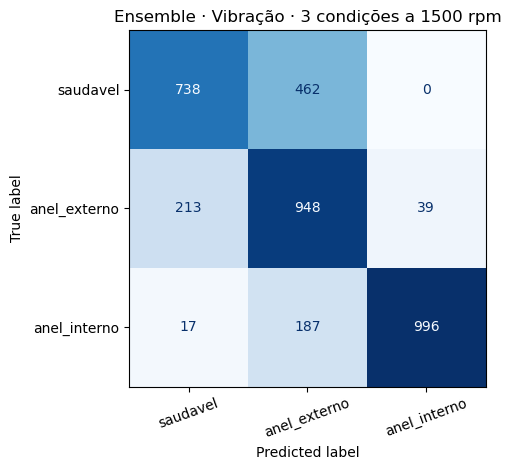

### Onde o ensemble erra · 3 condições a 1500 rpm
A matriz de confusão mostra **quais classes** se confundem. A taxa de acerto por rolamento mostra **quais rolamentos** causam os erros.

Esquema de rótulos: **artigo** (3 classes: saudável, anel externo, anel interno).

- **MCS:** a confusão mais frequente é **saudável prevista como anel interno** (499 amostras, 42 % da classe saudável). Os erros se concentram em 13 rolamentos com acerto abaixo de 60 %: KI04 (anel interno, nível 1): 2 %; K002 (saudável, 19 h de amaciamento): 14 %; KA30 (anel externo, nível 1): 20 %; K005 (saudável, 10 h de amaciamento): 21 %; KA15 (anel externo, nível 1): 22 %; KI21 (anel interno, nível 1): 24 %; K001 (saudável, >50 h de amaciamento): 33 %; K004 (saudável, 5 h de amaciamento): 38 %; KA22 (anel externo, nível 1): 39 %; K003 (saudável, 1 h de amaciamento): 40 %; KI14 (anel interno, nível 1): 47 %; KI16 (anel interno, nível 3): 50 %; KA16 (anel externo, nível 2): 51 %. No artigo, os erros deste sensor se concentraram em KA04 e KA22, ambos de nível 1. Em comum com este trabalho: KA22.

- **Vibração:** a confusão mais frequente é **saudável prevista como anel externo** (462 amostras, 38 % da classe saudável). Os erros se concentram em 4 rolamentos com acerto abaixo de 60 %: K005 (saudável, 10 h de amaciamento): 26 %; KI14 (anel interno, nível 1): 32 %; K002 (saudável, 19 h de amaciamento): 36 %; K004 (saudável, 5 h de amaciamento): 51 %. No artigo, os erros deste sensor se concentraram em KA04 e KI21, ambos de nível 1. Nenhum deles aparece entre os mais difíceis aqui.

- **Fusão:** a confusão mais frequente é **saudável prevista como anel externo** (460 amostras, 38 % da classe saudável). Os erros se concentram em 4 rolamentos com acerto abaixo de 60 %: K005 (saudável, 10 h de amaciamento): 27 %; KI14 (anel interno, nível 1): 32 %; K002 (saudável, 19 h de amaciamento): 36 %; K004 (saudável, 5 h de amaciamento): 51 %.

In [9]:
COND_1500 = ["N15_M07_F10", "N15_M01_F10", "N15_M07_F04"]
dados_4b = df[df["rolamento"].isin(rol_B) & df["condicao"].isin(COND_1500)].reset_index(drop=True)
div_4b = R.divisoes_artigo(dados_4b, cenario="B")
contexto_4b = ["torque_nm", "forca_n"]
print(f"{len(dados_4b)} amostras | {len(div_4b)} folds | condições: {sorted(dados_4b['condicao'].unique())}")

tab_sem_4b, preds_sem_4b, _ = rodar_por_sensor(dados_4b, div_4b, modelos)
tab_com_4b, preds_com_4b, _ = rodar_por_sensor(dados_4b, div_4b, modelos, extras=contexto_4b)
display(pd.concat({"sem_contexto": tab_sem_4b, "com_contexto": tab_com_4b}, axis=1))

# Acerto do ensemble em cada condição
display(pd.concat({s: R.acerto_por(preds_sem_4b[s], "Ensemble", "condicao")["taxa_acerto"]
                   for s in ("MCS", "Vibracao")}, axis=1).round(3))

plot_confusao(preds_sem_4b["Vibracao"], "Ensemble", "Ensemble · Vibração · 3 condições a 1500 rpm", nomes)
plt.show()
display(Markdown(R.relatorio_erros(preds_sem_4b, esquema,
                                   titulo="Onde o ensemble erra · 3 condições a 1500 rpm")))

In [10]:
comparacao = pd.DataFrame({
    "condição 0 (exp. 1)": tab_B.loc["Ensemble"],
    "3 condições a 1500 rpm (exp. 4b)": tab_sem_4b.loc["Ensemble"],
    "4 condições (exp. 4)": tab_sem.loc["Ensemble"],
}).T
comparacao

,MCS,Vibracao,Fusao
condição 0 (exp. 1),35.3,72.9,73.0
3 condições a 1500 rpm (exp. 4b),36.0,74.5,74.1
4 condições (exp. 4),38.5,70.4,70.5


## 7. Experimento 5 · Detecção binária com todos os rolamentos reais
Pergunta prática: **o rolamento está danificado?** Usamos todos os rolamentos saudáveis e com dano real (inclusive K006, KI17 e KB), as 4 condições, e `StratifiedGroupKFold` com 5 folds por rolamento.

Com mais rolamentos danificados que saudáveis, a acurácia sozinha engana. Por isso olhamos também a **acurácia balanceada** e o **F1 macro**.

acuracia        acuracia_bal        f1_macro       
             mean    std         mean    std     mean    std
modelo                                                      
Ensemble    0.854  0.080        0.831  0.154    0.808  0.139
RF          0.840  0.080        0.820  0.154    0.793  0.137
NN          0.833  0.080        0.817  0.139    0.789  0.119
CART        0.828  0.106        0.799  0.178    0.775  0.172
kNN         0.826  0.052        0.820  0.111    0.787  0.084
ELM         0.822  0.099        0.800  0.168    0.770  0.162
SVM         0.819  0.045        0.769  0.150    0.747  0.113
BT          0.814  0.084        0.786  0.151    0.757  0.139

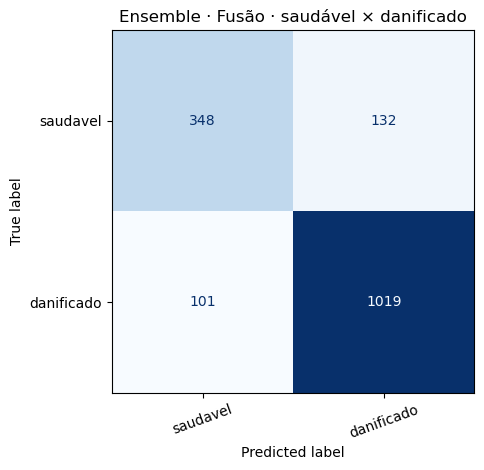

In [11]:
dados_bin = df[df["origem"] != "artificial"].reset_index(drop=True)
div_bin = R.divisoes_grupo(dados_bin.assign(classe=dados_bin["danificado"]), n_splits=5)
preds_bin, _ = R.avaliar(dados_bin, R.colunas_features(dados_bin, R.GRUPOS_SENSORES["Fusao"]),
                         div_bin, modelos, alvo="danificado", grades=R.GRADES, n_jobs=N_JOBS)
display(R.resumo(preds_bin).round(3))
plot_confusao(preds_bin, "Ensemble", "Ensemble · Fusão · saudável × danificado",
              {0: "saudavel", 1: "danificado"})

## 8. Salvar resultados
Salvamos as predições de cada amostra × modelo × fold. Isso permite refazer qualquer métrica ou gráfico sem treinar de novo. As tabelas-resumo também vão para CSV.

In [12]:
pd.concat({s: p for s, p in preds_B.items()}, names=["sensor"]).to_csv(PASTA_RESULTADOS / "predicoes_cenario_B.csv")
tab_B.to_csv(PASTA_RESULTADOS / "tabela_cenario_B.csv")
if esquema == "artigo":
    tab_C.to_csv(PASTA_RESULTADOS / "tabela_cenario_C.csv")
pd.concat({"sem_contexto": tab_sem, "com_contexto": tab_com}, axis=1).to_csv(PASTA_RESULTADOS / "tabela_4_condicoes.csv")
preds_bin.to_csv(PASTA_RESULTADOS / "predicoes_binario.csv", index=False)
print(sorted(p.name for p in PASTA_RESULTADOS.iterdir()))

['predicoes_binario.csv', 'predicoes_cenario_B.csv', 'tabela_4_condicoes.csv', 'tabela_cenario_B.csv', 'tabela_cenario_C.csv']


## Conclusão · Resultados obtidos × estudo de referência

**Configuração:** esquema de rótulos `artigo` (3 classes), seleção de features `razao` com d̄ ≥ 0,7, filtro de correlação |r| ≥ 0,95, validação por rolamento. O experimento 1b usou a seleção `artigo`.

### 1. Resumo dos experimentos (ensemble)

| # | Experimento | Validação | MCS | Vibração | Fusão | Artigo (MCS / Vib.) |
|---|---|---|---|---|---|---|
| 1 | Cenário B · 3 classes, condição 0 | Tabela 10 (10 comb.) | 35,3 | 72,9 | 73,0 | 93,3 / 98,3 (Tab. 11) |
| 1b | Cenário B · binário (seleção `artigo`)¹ | Tabela 10 (10 comb.) | 67,4 | 68,2 | 68,8 | – |
| 2 | Cenário C · com danos múltiplos KB | 20 comb. | 29,1 | 75,2 | 75,2 | 86,3 / 91,3 (Tab. 13) |
| 4 | 4 condições juntas | Tabela 10 (10 comb.) | 38,7 | 70,3 | 70,4 | – |
| 4b | 3 condições a 1500 rpm | Tabela 10 (10 comb.) | 36,0 | 74,7 | 74,2 | – |
| 5 | Binário, 20 rolamentos, 4 condições, fusão¹ | StratifiedGroupKFold (5) | – | – | 87,7 | – |

Acurácia média [%], exceto onde indicado. ¹ Valores de acurácia balanceada.

Melhores modelos individuais na vibração: SVM com 75,9 % (exp. 1), NN com 76,7 % (exp. 2) e SVM com 77,5 % (exp. 4b). O desvio padrão entre combinações é alto: cerca de 13 pontos no ensemble do experimento 1.

### 2. O que cada experimento mostrou

**Experimento 1 · cenário B**
- A vibração atingiu 72,9 % (ensemble) contra 98,3 % no artigo. A corrente ficou em 35,3 %, no nível do acaso (33 %), contra 93,3 % no artigo.
- Acerto por classe na vibração: anel interno 85 %, anel externo 77 %, saudável 58 %. Nenhum anel interno foi confundido com saudável. O erro dominante é **saudável previsto como anel externo** (170 de 400 amostras).
- Os rolamentos que concentram os erros são os saudáveis **K002 (8 %)** e **K005 (16 %)**, seguidos de KI14 (41 %), KA16 (60 %), K004 (65 %) e KA04 (69 %).

**Experimento 1b · binário**
- A vibração detecta dano em 91 % das amostras danificadas, mas acerta apenas 46 % das saudáveis. Os mesmos K002 (4 %) e K005 (0 %) quase sempre geram falso alarme.
- **Na tarefa binária, a corrente mostrou sinal:** acurácia balanceada de 67,4 % no ensemble e 75,7 % no ELM. É o único experimento em que a MCS supera o acaso com margem.

**Experimento 2 · cenário C**
- **Ao contrário do artigo, incluir os rolamentos KB não piorou o resultado.** A vibração subiu para 75,2 %, enquanto no artigo caiu cerca de 7 pontos. KB23 e KB24 foram classificados corretamente em 100 % das amostras, porque têm assinatura forte de anel interno.
- O KB27 (dominante no anel externo) teve 65 % de acerto. No artigo, ele foi classificado majoritariamente como anel interno.
- A MCS caiu para 29,1 %, abaixo do acaso.

**Experimentos 4 e 4b · múltiplas condições**
- Com as 4 condições juntas, a vibração cai para 70,3 %. A condição a **900 rpm (N09) é a mais difícil:** 56 % de acerto, contra 73 a 79 % nas demais.
- Removendo a N09 (exp. 4b), a vibração volta a 74,7 %, no nível do experimento 1. **A dificuldade de misturar condições vem quase toda da rotação.** Torque e força alteram pouco o desempenho, e a condição com menor força radial (N15_M07_F04) foi a melhor (80 %).
- **Os resultados "com contexto" foram idênticos aos "sem contexto".** As colunas de rotação, torque e força não separam as classes, e a etapa de seleção as descartou em todos os folds.

**Experimento 5 · detecção binária com todos os rolamentos**
- Foi o melhor resultado do trabalho: **acurácia balanceada de 87,7 %**, acurácia de 86,4 % e F1 macro de 83,6 % (ensemble, fusão).
- Acertos: 93 % das amostras danificadas e 71 % das saudáveis.
- Os erros de novo se concentram em **K005 (10 %)** e **K002 (25 %)**. Os demais 18 rolamentos ficaram entre 74 % e 100 %. A condição N09 é de novo a pior (79 %, contra 88 a 90 %).
- A melhora em relação ao experimento 1b se deve a mais rolamentos saudáveis no treino (6 no total, contra 5) e a mais dados (4 condições). A validação também é diferente (5 folds aleatórios por rolamento), então a comparação direta deve ser feita com cautela.

### 3. Concordâncias com o artigo

- **A vibração supera a corrente** em todos os experimentos de 3 classes.
- **Danos de nível 1 estão entre os mais difíceis.** KA04, apontado no artigo, também tem baixo acerto aqui (69 %), assim como KI14 (41 %).
- O SVM na vibração tem desempenho praticamente igual ao do artigo (75,9 % contra 75,8 %).

### 4. Divergências em relação ao artigo

- **Valores absolutos muito menores:** 72,9 % contra 98,3 % na vibração e 35,3 % contra 93,3 % na corrente.
- **A corrente não generaliza na classificação em 3 classes.** Em todos os experimentos multiclasse ela ficou entre 29 % e 39 %, e o acerto por rolamento variou de 0 % a 84 % dentro da mesma classe.
- **Os KB não derrubaram o desempenho** e o KB27 não foi confundido majoritariamente com anel interno.
- **O ensemble não foi o melhor modelo.** SVM e NN o superaram na vibração.

### 5. Achados metodológicos

1. **Com o critério `razao` e d̄ ≥ 0,7, a seleção manteve só 3 features em quase todos os folds,** o mínimo garantido por `min_features`: `env_fr`, `env_bpfi_1x` e `env_bpfi_2x`. Isso tem três consequências:
   - todas são assinaturas de **anel interno**, e o anel externo é reconhecido indiretamente, por exclusão;
   - nenhuma feature de corrente sobrevive na fusão, por isso **Fusão ≈ Vibração** em todos os experimentos;
   - as variáveis de contexto do experimento 4 foram descartadas.

   O limiar 0,7 foi calibrado para a fórmula do artigo e é restritivo demais para o critério `razao`.
2. **O critério de seleção ideal depende da tarefa.** `razao` foi melhor na vibração com 3 classes (+8,6 pontos). `artigo` foi melhor na corrente com 2 classes (67,4 % contra ≈ 50 %).
3. **K002 e K005 são o principal limitador em todos os experimentos.** São classificados como danificados com qualquer critério, validação ou conjunto de dados. Esses dois rolamentos saudáveis têm vibração semelhante à de rolamentos danificados.

### 6. Possíveis explicações para a diferença

1. **Features diferentes.** O artigo usa 23 features descritas em outro trabalho (Kimotho & Sextro, 2014), sem detalhar os parâmetros. As features deste trabalho foram reconstruídas e não são idênticas.
2. **Validação possivelmente mais rigorosa.** Aqui, normalização e seleção são ajustadas só com os rolamentos de treino de cada combinação. O artigo não informa como fez essas etapas. Se foram feitas com todos os dados, os resultados de lá podem estar otimistas. Isso é uma hipótese, não algo que o artigo permita confirmar.
3. **Limitações do conjunto de dados:** apenas 5 a 6 rolamentos saudáveis, dois deles atípicos, e 4 dos 5 rolamentos de anel externo com dano de nível 1.

### 7. Síntese

O trabalho **confirma as tendências qualitativas** do artigo: a vibração é mais informativa que a corrente, e os danos leves e alguns rolamentos específicos concentram os erros. Mas **não reproduz os valores absolutos**. Com divisão rigorosa por rolamento, a vibração atinge 73 a 77 % na classificação em 3 classes, e a corrente só traz informação útil na detecção binária. Como **detector de dano** (saudável × danificado, exp. 5), o sistema chega a 87,7 % de acurácia balanceada, um resultado aplicável na prática. O maior limitador é a **variabilidade entre rolamentos**, em especial os saudáveis K002 e K005, e não a escolha do algoritmo.
